In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [3]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"

df = pd.read_csv(url)

print("Dataset Loaded Successfully!")

Dataset Loaded Successfully!


In [4]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
df.tail()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
886,0,2,male,27.0,0,0,13.00,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.00,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.45,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.00,C,First,man,True,C,Cherbourg,yes,True
890,0,3,male,32.0,0,0,7.75,Q,Third,man,True,NaN,Queenstown,no,True


In [6]:
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])

print("Total Columns:", df.shape[1])

Dataset Shape: (891, 15)
Total Rows: 891
Total Columns: 15


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    object 
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    object 
 8   class        891 non-null    object 
 9   who          891 non-null    object 
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    object 
 12  embark_town  889 non-null    object 
 13  alive        891 non-null    object 
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), object(7)
memory usage: 92.4+ KB


In [8]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [9]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [10]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

survived        0.000000
pclass          0.000000
sex             0.000000
age            19.865320
sibsp           0.000000
parch           0.000000
fare            0.000000
embarked        0.224467
class           0.000000
who             0.000000
adult_male      0.000000
deck           77.216611
embark_town     0.224467
alive           0.000000
alone           0.000000
dtype: float64


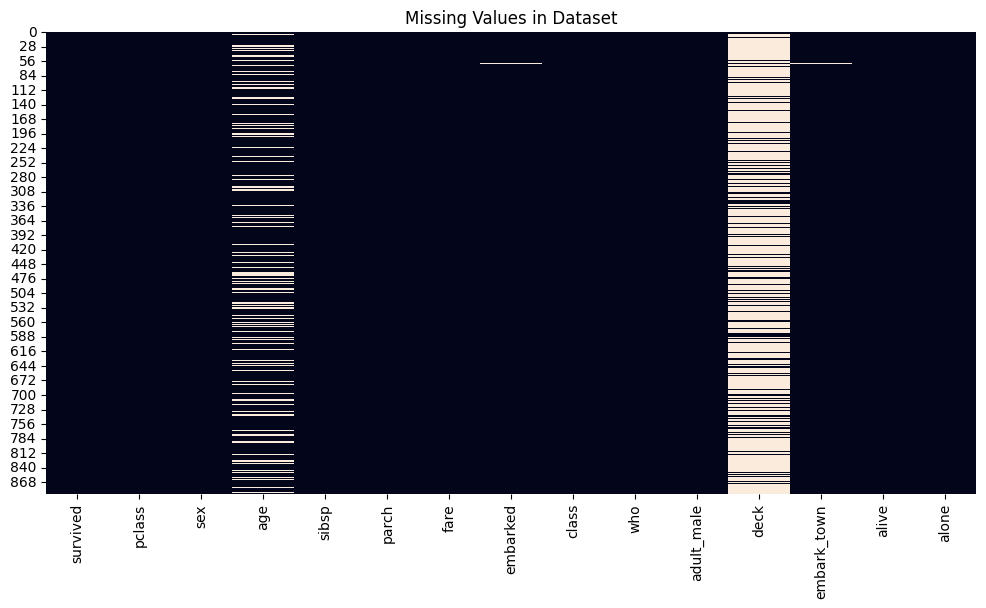

In [11]:
plt.figure(figsize=(12, 6))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Dataset")

plt.show()

In [12]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 107


In [13]:
df = df.drop_duplicates()

print("Duplicates Removed Successfully!")

Duplicates Removed Successfully!


In [14]:
print("Remaining Duplicates:", df.duplicated().sum())

Remaining Duplicates: 0


In [15]:
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

In [16]:
columns_to_lower = [
    "sex",
    "embarked",
    "class",
    "who",
    "embark_town",
    "alive"
]

for col in columns_to_lower:
    df[col] = df[col].str.lower()

In [17]:
df["age"] = df["age"].fillna(df["age"].median())

In [18]:
df["embarked"] = df["embarked"].fillna(df["embarked"].mode()[0])

In [20]:
df["deck"] = df["deck"].astype("category")
df["deck"] = df["deck"].cat.add_categories("Unknown")
df["deck"] = df["deck"].fillna("Unknown")

In [21]:
df["embark_town"] = df["embark_town"].fillna(
    df["embark_town"].mode()[0]
)

In [22]:
print(df.dtypes)

survived          int64
pclass            int64
sex              object
age             float64
sibsp             int64
parch             int64
fare            float64
embarked         object
class            object
who              object
adult_male         bool
deck           category
embark_town      object
alive            object
alone              bool
dtype: object


In [23]:
df["survived"] = df["survived"].astype(int)

df["pclass"] = df["pclass"].astype(int)

df["sibsp"] = df["sibsp"].astype(int)

df["parch"] = df["parch"].astype(int)

In [24]:
print("Missing Values After Cleaning:")

print(df.isnull().sum())

Missing Values After Cleaning:
survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
deck           0
embark_town    0
alive          0
alone          0
dtype: int64


In [25]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [26]:
df.info()

print("\nFinal Dataset Shape:", df.shape)

df.head(10)

<class 'pandas.core.frame.DataFrame'>
Index: 784 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     784 non-null    int64   
 1   pclass       784 non-null    int64   
 2   sex          784 non-null    object  
 3   age          784 non-null    float64 
 4   sibsp        784 non-null    int64   
 5   parch        784 non-null    int64   
 6   fare         784 non-null    float64 
 7   embarked     784 non-null    object  
 8   class        784 non-null    object  
 9   who          784 non-null    object  
 10  adult_male   784 non-null    bool    
 11  deck         784 non-null    category
 12  embark_town  784 non-null    object  
 13  alive        784 non-null    object  
 14  alone        784 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), object(6)
memory usage: 82.3+ KB

Final Dataset Shape: (784, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.00,1,0,7.2500,s,third,man,True,Unknown,southampton,no,False
1,1,1,female,38.00,1,0,71.2833,c,first,woman,False,C,cherbourg,yes,False
2,1,3,female,26.00,0,0,7.9250,s,third,woman,False,Unknown,southampton,yes,True
3,1,1,female,35.00,1,0,53.1000,s,first,woman,False,C,southampton,yes,False
4,0,3,male,35.00,0,0,8.0500,s,third,man,True,Unknown,southampton,no,True
5,0,3,male,28.25,0,0,8.4583,q,third,man,True,Unknown,queenstown,no,True
6,0,1,male,54.00,0,0,51.8625,s,first,man,True,E,southampton,no,True
7,0,3,male,2.00,3,1,21.0750,s,third,child,False,Unknown,southampton,no,False
8,1,3,female,27.00,0,2,11.1333,s,third,woman,False,Unknown,southampton,yes,False
9,1,2,female,14.00,1,0,30.0708,c,second,child,False,Unknown,cherbourg,yes,False


In [27]:
df.to_csv("Titanic_Cleaned.csv", index=False)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [28]:
from google.colab import files

files.download("Titanic_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>